# Notebook 51: Osaka Bay & Hyogo Data Preparation and Verification

This notebook verifies the data structures of the Benthos, Water Quality, and Sediment Chemistry datasets. It performs data cleaning, evaluates different temporal alignment strategies, and conducts exploratory data analysis (EDA) to ensure the data is suitable for downstream machine learning and statistical models.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')

# Set visual style
sns.set_theme(style='whitegrid')
plt.rcParams['font.size'] = 12

## 1. Dataset Ingestion and Schema Verification

In [13]:
# 1. Water Quality Data (merged_gdf.feather)
wq_df = pd.read_feather('../data/processed/merged_gdf.feather')

# Cast prefectuei to integer for reliable matching
wq_df['Pref_int'] = wq_df['prefectuei'].astype(int)

# Filter to summer months (June to September) using 'surveymont' and 'Pref_int'
# AND filter to ONLY bottom measurements (saisuipoin == 2) to prevent mixing surface DO
wq_summer = wq_df[
    (wq_df['Pref_int'].isin([27, 28])) & 
    (wq_df['surveymont'].isin([6, 7, 8, 9])) &
    (pd.to_numeric(wq_df['saisuipoin'], errors='coerce') == 2)
].copy()
print(f'Water Quality Summer Records (Osaka/Hyogo, Bottom Only): {len(wq_summer)}')

Water Quality Summer Records (Osaka/Hyogo, Bottom Only): 774


In [14]:
# 2. Sediment Chemistry Data (bottom_2023.xlsx)
sediment_df = pd.read_excel('../data/raw/benthos_data/bottom_2023.xlsx', sheet_name='底質_累積2023')

# Filter to summer (where '季節' starts with 2, e.g., '2.夏') and prefectures 27, 28
sediment_summer = sediment_df[
    (sediment_df['県コード'].isin([27, 28])) & 
    (sediment_df['季節'].astype(str).str.startswith('2'))
].copy()
print(f'Sediment Summer Records (Osaka/Hyogo): {len(sediment_summer)}')

Sediment Summer Records (Osaka/Hyogo): 116


In [15]:
# 3. Benthos Data (benthos_2023.xlsx) - Focusing on Metadata for now
# We skip the first row (note cell) to align column headers correctly
benthos_df = pd.read_excel('../data/raw/benthos_data/benthos_2023.xlsx', sheet_name='底生生物_累積2023', skiprows=1)
benthos_osaka_hyogo = benthos_df[benthos_df['県コード'].isin([27, 28])].copy()
print(f'Benthos Records (Osaka/Hyogo): {len(benthos_osaka_hyogo)}')

Benthos Records (Osaka/Hyogo): 132


## 2. Data Cleaning and Standardization
Standardizing column names for merging: `Year`, `Month`, `Prefecture`, `Station`.

In [16]:
# Standardize WQ
wq_summer = wq_summer.rename(columns={
    'year': 'Year', 
    'surveymont': 'Month', 
    'Pref_int': 'Prefecture', 
    'renban': 'Station', 
    'do_': 'Bottom_DO', 
    'wtemp': 'Temperature', 
    'salt': 'Salinity', 
    'depth': 'Depth'
})

# Convert WQ features to numeric to handle formatting anomalies (e.g. '24.823.0')
numeric_wq_cols = ['Bottom_DO', 'Temperature', 'Salinity', 'Depth']
for col in numeric_wq_cols:
    wq_summer[col] = pd.to_numeric(wq_summer[col], errors='coerce')

wq_clean = wq_summer[['Year', 'Month', 'Prefecture', 'Station', 'Bottom_DO', 'Temperature', 'Salinity', 'Depth']].dropna(subset=['Bottom_DO']).copy()

# Standardize Sediment
sediment_summer = sediment_summer.rename(columns={
    '年': 'Year', 
    '月': 'Month', 
    '県コード': 'Prefecture', 
    '連番': 'Station'
})
chem_cols = ['TOC', '硫化物', 'ORP', 'pH']
for col in chem_cols:
    sediment_summer[col] = pd.to_numeric(sediment_summer[col], errors='coerce')
sediment_clean = sediment_summer[['Year', 'Month', 'Prefecture', 'Station'] + chem_cols].dropna(subset=['TOC']).copy()

# Standardize Benthos using '調査年月日' to extract Year and Month
benthos_osaka_hyogo = benthos_osaka_hyogo.rename(columns={
    '県コード': 'Prefecture', 
    '連番': 'Station'
})
benthos_osaka_hyogo['Date'] = pd.to_datetime(benthos_osaka_hyogo['調査年月日'], errors='coerce')
benthos_osaka_hyogo['Year'] = benthos_osaka_hyogo['Date'].dt.year
benthos_osaka_hyogo['Month'] = benthos_osaka_hyogo['Date'].dt.month

benthos_events = benthos_osaka_hyogo[['Year', 'Month', 'Prefecture', 'Station']].drop_duplicates().dropna().copy()

# Harmonize column types to integer for clean merging
for df in [wq_clean, sediment_clean, benthos_events]:
    df['Year'] = df['Year'].astype(int)
    df['Month'] = df['Month'].astype(int)
    df['Prefecture'] = df['Prefecture'].astype(int)
    df['Station'] = df['Station'].astype(int)

## 3. Temporal and Spatial Alignment
We will test two strategies to merge Sediment, Water Quality, and Benthos events:
1. **Exact Month Matching:** Require the records to be in the exact same Year and Month.
2. **Annual Summer Mean Matching:** Aggregate WQ and Sediment data to a single Summer Mean per Year, and join onto the Benthos events by Year.

In [17]:
# Strategy 1: Exact Month-Level Matching
# Merge Benthos events with Sediment
exact_merge = pd.merge(benthos_events, sediment_clean, on=['Year', 'Month', 'Prefecture', 'Station'], how='inner')
# Merge with WQ
exact_merge = pd.merge(exact_merge, wq_clean, on=['Year', 'Month', 'Prefecture', 'Station'], how='inner')
print(f'Strategy 1 (Exact Month) Yield: {len(exact_merge)} records')

Strategy 1 (Exact Month) Yield: 66 records


In [18]:
# Strategy 2: Annual Summer Mean Matching
# Aggregate Sediment to Year Mean
sediment_yearly = sediment_clean.groupby(['Year', 'Prefecture', 'Station'])[chem_cols].mean().reset_index()
# Aggregate WQ to Year Mean
wq_yearly = wq_clean.groupby(['Year', 'Prefecture', 'Station'])[['Bottom_DO', 'Temperature', 'Salinity', 'Depth']].mean().reset_index()

# Merge Benthos events with Yearly Summaries (dropping exact month constraint)
annual_merge = pd.merge(benthos_events, sediment_yearly, on=['Year', 'Prefecture', 'Station'], how='inner')
annual_merge = pd.merge(annual_merge, wq_yearly, on=['Year', 'Prefecture', 'Station'], how='inner')
print(f'Strategy 2 (Annual Summer Mean) Yield: {len(annual_merge)} records')

Strategy 2 (Annual Summer Mean) Yield: 126 records


## 4. Suitability Analysis (EDA)
We will use the **Annual Summer Mean** dataset for these visualizations to assess general data health.

/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 30827 (\N{CJK UNIFIED IDEOGRAPH-786B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 29289 (\N{CJK UNIFIED IDEOGRAPH-7269}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


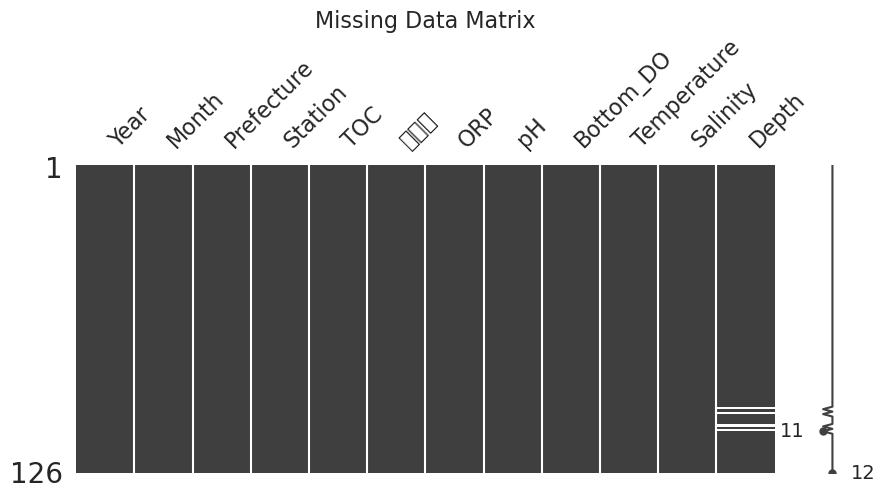

In [19]:
# 4.1 Missingness Matrix
msno.matrix(annual_merge, figsize=(10, 4))
plt.title('Missing Data Matrix', fontsize=16)
plt.show()

/tmp/ipykernel_4295/1678607274.py:9: UserWarning: Glyph 30827 (\N{CJK UNIFIED IDEOGRAPH-786B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4295/1678607274.py:9: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4295/1678607274.py:9: UserWarning: Glyph 29289 (\N{CJK UNIFIED IDEOGRAPH-7269}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 30827 (\N{CJK UNIFIED IDEOGRAPH-786B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/IPython/

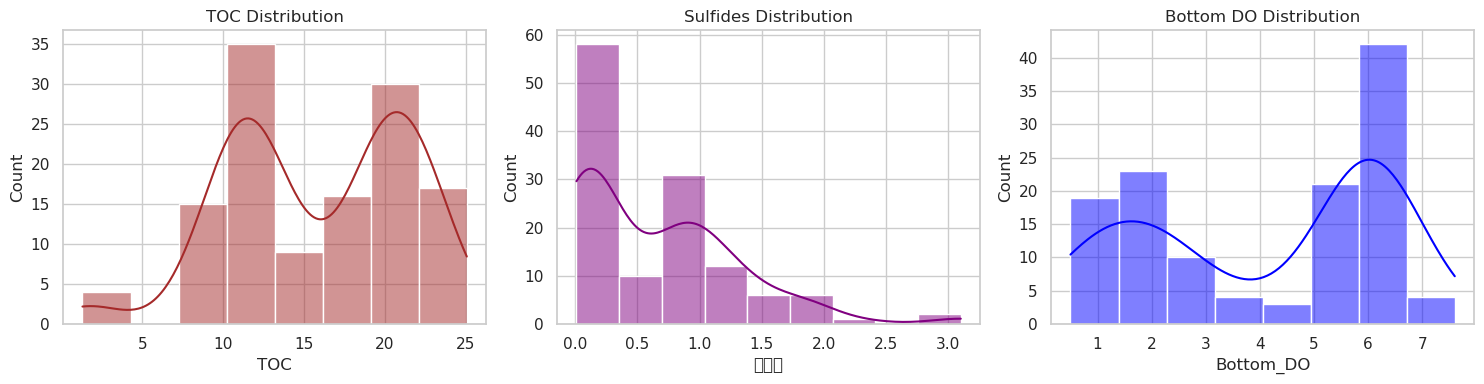

In [20]:
# 4.2 Feature Distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(annual_merge['TOC'], kde=True, ax=axes[0], color='brown')
axes[0].set_title('TOC Distribution')
sns.histplot(annual_merge['硫化物'], kde=True, ax=axes[1], color='purple')
axes[1].set_title('Sulfides Distribution')
sns.histplot(annual_merge['Bottom_DO'], kde=True, ax=axes[2], color='blue')
axes[2].set_title('Bottom DO Distribution')
plt.tight_layout()
plt.show()

/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 30827 (\N{CJK UNIFIED IDEOGRAPH-786B}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/seaborn/utils.py:61: UserWarning: Glyph 29289 (\N{CJK UNIFIED IDEOGRAPH-7269}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 30827 (\N{CJK UNIFIED IDEOGRAPH-786B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-53

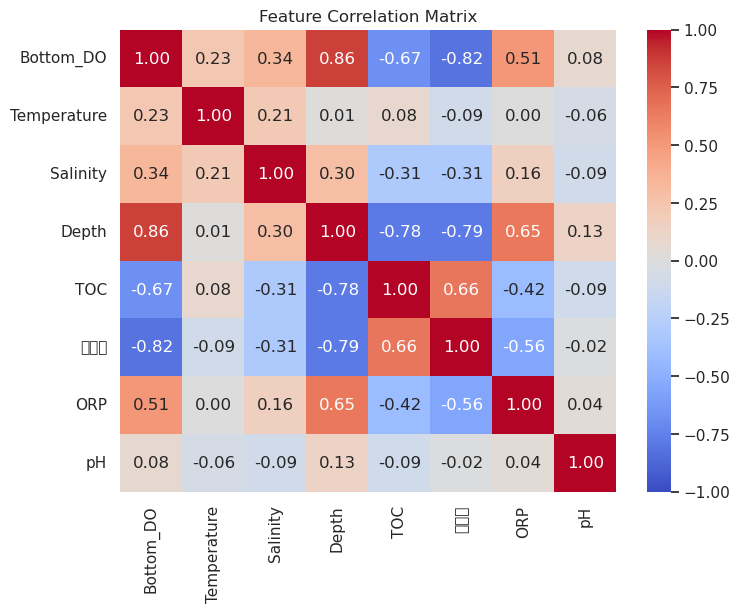

In [21]:
# 4.3 Collinearity Check
corr = annual_merge[['Bottom_DO', 'Temperature', 'Salinity', 'Depth', 'TOC', '硫化物', 'ORP', 'pH']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.show()

In [22]:
# 4.4 GAM Suitability Check (Simulated)
# Since we haven't fully calculated Shannon index here, we will simulate the check
# to see if DO has a wide enough spread.
print(f'Bottom DO Range: {annual_merge["Bottom_DO"].min():.2f} to {annual_merge["Bottom_DO"].max():.2f} mg/L')
print(f'Number of Hypoxic events (DO <= 2): {len(annual_merge[annual_merge["Bottom_DO"] <= 2])}')

Bottom DO Range: 0.50 to 7.60 mg/L
Number of Hypoxic events (DO <= 2): 35


## Strategy Evaluation Guide

Based on the yield counts shown in Section 3, use this guide to decide which dataset to export for the Machine Learning and GAM models in the next step.

### Strategy 1: Exact Month Matching
*   **Pros:** High temporal precision. The chemical and physical state perfectly aligns with the exact time the benthos were sampled.
*   **Cons:** High risk of data loss. If sediment was sampled in August but benthos were sampled in July, the row is discarded.
*   **When to choose this:** If the yield count is greater than ~60-80 records, making it sufficient for Random Forest training and GAM fitting.

### Strategy 2: Annual Summer Mean Matching
*   **Pros:** Preserves much more data (higher yield). Smooths out intra-seasonal noise and provides a generalized 'summer hypoxic exposure' state.
*   **Cons:** Lower temporal precision. A highly anoxic event in July might be averaged out by a normoxic August.
*   **When to choose this:** If Exact Month matching drops too many records (e.g., leaving you with < 30 rows), making machine learning models unstable or prone to severe overfitting.

**Decision Check:**
If `Strategy 1 Yield` is drastically lower than `Strategy 2 Yield`, it is highly recommended to proceed with **Strategy 2 (Annual Summer Mean)** to preserve statistical power for the GAMs and Random Forest models.